# ``meshlab`` - Tutorial 0

**Surfaces definition**


## 1. Import packages
---


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from functions.create_polygon import create_polygon

from meshlab.core import Mesh, Curve, Contour
from meshlab.operations import insert_contour
from meshlab.utils import plot_mesh

## 2. Geometries definition
---

Circle


In [17]:
# Geometric parameters
center = np.array([-2.0, 0.0])
radius = 1.0
num_circle_points = 50

# Counter-clockwise direction
angles = np.linspace(0.0, 2.0 * np.pi, num_circle_points, endpoint=False)
circle_points = center + radius * np.column_stack((np.cos(angles), np.sin(angles)))

# Close curve
circle_points = np.vstack((circle_points, circle_points[0]))

# Define contour
circle = Contour("circle", [Curve("circle", circle_points)])

Square


In [18]:
# Geometric parameters
vertice_1 = [1.0,-1.0]
vertice_2 = [3.0,-1.0]
vertice_3 = [3.0, 1.0]
vertice_4 = [1.0, 1.0]

points_per_edge = 12

# Counter-clockwise direction
square_points = create_polygon(
    vertices=[vertice_1, vertice_2, vertice_3, vertice_4,],
    points_per_edge=[points_per_edge] * 4,
)

# Close curve
square_points = np.vstack((square_points, square_points[0]))

# Define contour
square = Contour("square", [Curve("square", square_points)])

## 3. Rectangular domain
---

In [19]:
# Domain limits
xmin, xmax = -5.0, 5.0
ymin, ymax = -3.0, 3.0

# External contour in a clockwise direction
inlet = Curve("inlet", np.linspace([xmin, ymin], [xmin, ymax], 17))
laterals_upper = Curve("laterals_upper", np.linspace([xmin, ymax], [xmax, ymax], 41))
outlet = Curve("outlet", np.linspace([xmax, ymax], [xmax, ymin], 17))
laterals_lower = Curve("laterals_lower", np.linspace([xmax, ymin], [xmin, ymin], 41))

# Contour definition
domain = Contour("outer_domain", [inlet, laterals_upper, outlet, laterals_lower])

## 4. Creating mesh surfaces
---

In [20]:
# 2D mesh definition
mesh = Mesh(dim=2)

# Insert contours
insert_contour(mesh, domain)
insert_contour(mesh, circle)
insert_contour(mesh, square)

## 5. Visualize surfaces
---

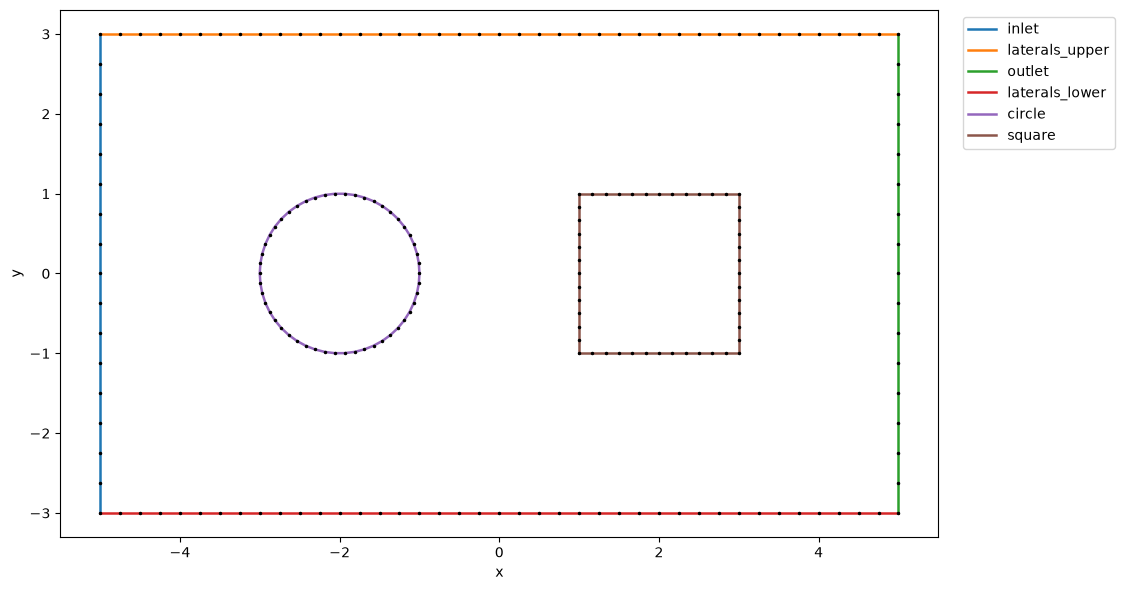

In [22]:
figure, ax = plot_mesh(mesh, show=False)

figure.set_size_inches(11, 6)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()

plt.show()